# AuraSync — Retail Strategist & Economist Agent: H&M Customer Analytics

This notebook builds the training ground for the **Retail Strategist Agent** and **Economist Agent**:

1. **RFM Analysis** — segment customers by Recency, Frequency, Monetary value
2. **CLTV Estimation** — deterministic customer lifetime value scoring
3. **Association Rule Learning (ARL)** — "Complete the Look" product-pairing rules

**Data:** H&M Personalized Fashion Recommendations (Kaggle). This run uses a **filtered slice**:
`transactions_filtered.csv` — 2020-09-01 to 2020-09-22 (22 days), 798,269 transactions, 189,510 customers, 26,252 articles.

> ⚠️ **Window caveat:** 22 days is short for RFM/CLTV — 75.8% of customers in this slice bought on only one day, so `Frequency` is doing less work than it would over a 6–12 month window. The segments below are directionally correct and fine for building/testing the pipeline, but before this feeds a real agent, re-run it on a longer transaction slice (e.g. 6–12 months) for meaningful frequency and churn signal.

**Expected folder layout** (same directory as this notebook):
```
articles.csv
customers.csv
transactions_filtered.csv
```


In [1]:
# One-time environment fix: this kernel was missing mlxtend, which the
# ARL step below needs (fpgrowth / association_rules). Safe to re-run —
# a no-op if already installed.
%pip install -q mlxtend


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import timedelta
from sklearn.preprocessing import MinMaxScaler
from mlxtend.frequent_patterns import fpgrowth, association_rules

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100


## 1. Load & merge data

In [3]:
articles = pd.read_csv('/Users/mac/Downloads/articles.csv')
customers = pd.read_csv('/Users/mac/Downloads/customers.csv')
tx = pd.read_csv('/Users/mac/Downloads/transactions_filtered.csv', parse_dates=['t_dat'])

print(f"articles:     {articles.shape}")
print(f"customers:    {customers.shape}")
print(f"transactions: {tx.shape}")
print(f"date range:   {tx['t_dat'].min().date()} -> {tx['t_dat'].max().date()}")


articles:     (105542, 25)
customers:    (1371980, 7)
transactions: (798269, 5)
date range:   2020-09-01 -> 2020-09-22


In [4]:
# Merge transaction line-items with customer and article attributes
df = tx.merge(
    customers[['customer_id', 'age', 'club_member_status', 'fashion_news_frequency']],
    on='customer_id', how='left'
)
df = df.merge(
    articles[['article_id', 'product_type_name', 'product_group_name', 'department_name',
              'index_name', 'section_name', 'garment_group_name', 'colour_group_name']],
    on='article_id', how='left'
)

print("Merged shape:", df.shape)
df.isna().sum().to_frame('n_missing').query('n_missing > 0')


Merged shape: (798269, 15)


,n_missing
age,2931
club_member_status,1358
fashion_news_frequency,1752


## 2. Quick EDA

`price` is normalized by H&M to a relative [0, 1] scale, not real currency — treat all monetary figures below as **relative units**, useful for ranking/segmenting customers against each other, not as literal dollar amounts.


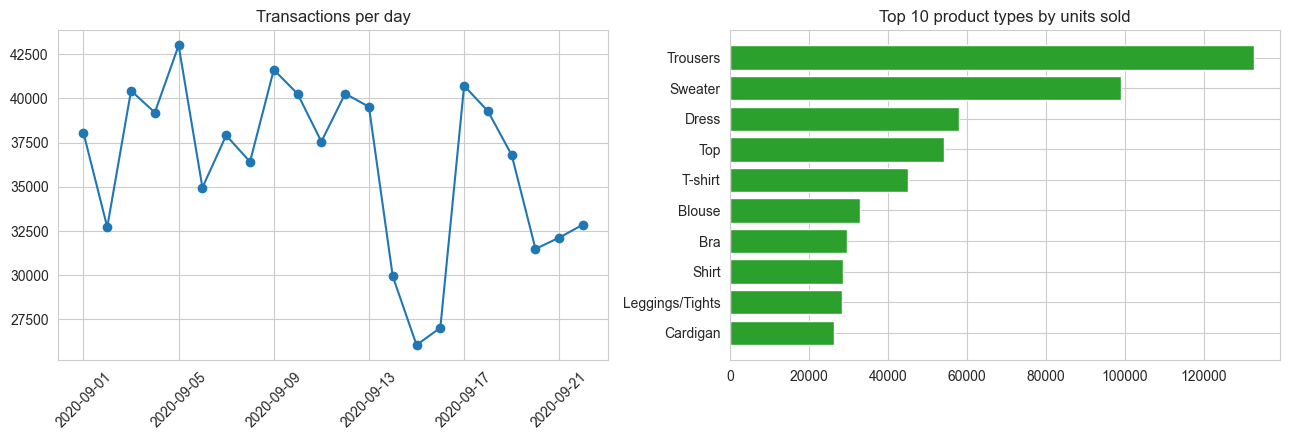

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

daily = df.groupby(df['t_dat'].dt.date).size()
axes[0].plot(daily.index, daily.values, marker='o', color='#1f77b4')
axes[0].set_title('Transactions per day')
axes[0].tick_params(axis='x', rotation=45)

top_types = df['product_type_name'].value_counts().head(10)
axes[1].barh(top_types.index[::-1], top_types.values[::-1], color='#2ca02c')
axes[1].set_title('Top 10 product types by units sold')

plt.tight_layout()
plt.show()


In [6]:
revenue_by_dept = df.groupby('department_name')['price'].sum().sort_values(ascending=False).head(10)
print("Top 10 departments by revenue (relative units):")
revenue_by_dept


Top 10 departments by revenue (relative units):


department_name
Knitwear          3102.617051
Trouser           1760.696339
Outwear           1587.686407
Blouse            1333.927407
Denim Trousers    1227.533712
Trousers          1054.729441
Jersey             954.576220
Dress              785.157339
Jersey Basic       715.069763
Basic 1            706.487085
Name: price, dtype: float64

## 3. RFM Analysis

- **Recency** — days since last purchase (relative to day after the last date in the slice)
- **Frequency** — number of distinct days the customer purchased on
- **Monetary** — total spend (relative units)

Each metric is scored 1–5 by quintile, combined into an RF code, and mapped to the standard RFM segment taxonomy.


In [7]:
snapshot_date = df['t_dat'].max() + timedelta(days=1)

rfm = df.groupby('customer_id').agg(
    Recency=('t_dat', lambda x: (snapshot_date - x.max()).days),
    Frequency=('t_dat', 'nunique'),
    Monetary=('price', 'sum')
).reset_index()

rfm['R_score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F_score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M_score'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['RF_score'] = rfm['R_score'].astype(str) + rfm['F_score'].astype(str)

seg_map = {
    r'[1-2][1-2]': 'hibernating',
    r'[1-2][3-4]': 'at_risk',
    r'[1-2]5': 'cant_lose',
    r'3[1-2]': 'about_to_sleep',
    r'33': 'need_attention',
    r'[3-4][4-5]': 'loyal_customers',
    r'41': 'promising',
    r'51': 'new_customers',
    r'[4-5][2-3]': 'potential_loyalists',
    r'5[4-5]': 'champions'
}
rfm['segment'] = rfm['RF_score'].replace(seg_map, regex=True)

rfm[['Recency', 'Frequency', 'Monetary']].describe()


,Recency,Frequency,Monetary
count,189510.000000,189510.000000,189510.000000
mean,10.893130,1.350330,0.141435
std,6.352004,0.774491,0.174272
min,1.000000,1.000000,0.001000
25%,5.000000,1.000000,0.044034
50%,11.000000,1.000000,0.084712
75%,16.000000,1.000000,0.169424
max,22.000000,19.000000,7.005390


In [8]:
seg_summary = rfm.groupby('segment').agg(
    customers=('customer_id', 'count'),
    avg_recency=('Recency', 'mean'),
    avg_frequency=('Frequency', 'mean'),
    avg_monetary=('Monetary', 'mean')
).sort_values('customers', ascending=False)

seg_summary

,customers,avg_recency,avg_frequency,avg_monetary
segment,,,,
loyal_customers,35072,8.699732,1.924869,0.202062
hibernating,33071,18.071241,1.000000,0.099510
at_risk,31086,17.994081,1.049572,0.104565
potential_loyalists,27995,4.803108,1.000000,0.109170
champions,20329,2.456687,2.256087,0.247643
about_to_sleep,14797,11.522741,1.000000,0.103553
promising,7458,6.760392,1.000000,0.104930
need_attention,7299,11.519797,1.000000,0.104318
new_customers,6520,2.534969,1.000000,0.113668


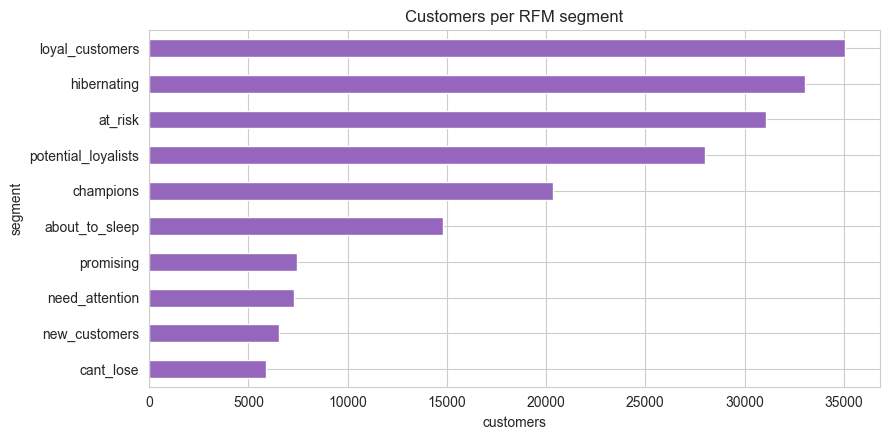

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
seg_summary['customers'].sort_values().plot(kind='barh', ax=ax, color='#9467bd')
ax.set_title('Customers per RFM segment')
ax.set_xlabel('customers')
plt.tight_layout()
plt.show()


## 4. CLTV Estimation (deterministic)

Classic formula-based CLTV — same approach as the FLO CLTV project:

```
Average Order Value  = total_price / total_transaction                (per customer)
Purchase Frequency   = total_transaction / total_number_of_customers   (per customer)
Repeat Rate          = customers with >1 transaction / all customers   (single value)
Churn Rate           = 1 - Repeat Rate
Profit Margin        = total_price * 0.10                              (assumes 10% margin — tune this)
Customer Value (CV)  = Average Order Value * Purchase Frequency
CLTV                 = (CV / Churn Rate) * Profit Margin
```

Because `price` is on H&M's normalized scale, raw CLTV values come out as tiny fractions — fine for *ranking* customers against each other, unreadable as a headline number. So we also min-max scale it to a 0–100 "CLTV score" for presentation, exactly like the classic tutorial does.

A probabilistic model (BG/NBD + Gamma-Gamma) would give a more defensible forward-looking CLTV, but it needs longer, more complete purchase histories per customer than this 22-day slice provides — worth revisiting once you pull a longer window.


In [10]:
cltv_c = df.groupby('customer_id').agg(
    total_transaction=('t_dat', 'nunique'),
    total_price=('price', 'sum')
).reset_index()

cltv_c['avg_order_value'] = cltv_c['total_price'] / cltv_c['total_transaction']
cltv_c['purchase_frequency'] = cltv_c['total_transaction'] / cltv_c.shape[0]

repeat_rate = (cltv_c['total_transaction'] > 1).sum() / cltv_c.shape[0]
churn_rate = 1 - repeat_rate

cltv_c['profit_margin'] = cltv_c['total_price'] * 0.10
cltv_c['CV'] = cltv_c['avg_order_value'] * cltv_c['purchase_frequency']
cltv_c['CLTV'] = (cltv_c['CV'] / churn_rate) * cltv_c['profit_margin']

cltv_c['cltv_score'] = MinMaxScaler(feature_range=(0, 100)).fit_transform(cltv_c[['CLTV']])
cltv_c['cltv_segment'] = pd.qcut(cltv_c['CLTV'], 4, labels=['D', 'C', 'B', 'A'])

print(f"repeat_rate: {repeat_rate:.3f}   churn_rate: {churn_rate:.3f}")
cltv_c.sort_values('cltv_score', ascending=False)[
    ['customer_id', 'total_transaction', 'total_price', 'cltv_score', 'cltv_segment']
].head(10)


repeat_rate: 0.241   churn_rate: 0.759


,customer_id,total_transaction,total_price,cltv_score,cltv_segment
169361,e4ea6ece6706e9c119a3640e09e842f5ae7d62a6b546d4...,1,7.005390,100.000000,A
41935,3860b5e65d48bb509d89e6b21ec0458e13c75eab2e95f5...,1,4.677898,44.589944,A
184084,f894f1fa24e7f19f7e2586a30780e34b084854417c4675...,4,4.241915,36.665646,A
88718,77db96923d20d40532eba0020b55cd91eb51358885c2d6...,6,3.526644,25.343035,A
125764,a9948bc6e5234770cfe5669f8f9b5c4261e87ccb1846d7...,5,3.506322,25.051801,A
63489,559ca47a6cff69d0fd55015f961f0a82bf84f17f18faca...,4,3.263339,21.700000,A
172337,e8f138aa177d338aaa0f6596504e142dc1070e63cae575...,10,3.210695,21.005520,A
151219,cc0154ca9f570ba4b12a3db5861c008949a3e05e4489c9...,10,3.188932,20.721726,A
62979,54e8ebd39543b5a4d69c3e7d79977558d2a606e6540ba0...,3,3.161169,20.362491,A
33182,2cabdc6101018f8cea44310343769715049befed47caa9...,6,3.145237,20.157756,A


In [11]:
cltv_c.groupby('cltv_segment', observed=True)['cltv_score'].agg(['count', 'mean', 'min', 'max'])

,count,mean,min,max
cltv_segment,,,,
D,47523,0.001847,0.000000,0.003949
C,47831,0.008545,0.003949,0.014621
B,46820,0.031064,0.014621,0.058488
A,47336,0.369727,0.058488,100.000000


## 5. Association Rule Learning — "Complete the Look"

Basket = everything one customer bought on one day, at `product_type_name` granularity (article-level is too sparse for meaningful support across 26k articles). Only baskets with 2+ distinct product types can contribute a rule, so single-item baskets are dropped before mining. Using `fpgrowth` (faster than `apriori` at this basket count).


In [12]:
basket = (df.groupby(['customer_id', 't_dat', 'product_type_name'])['article_id']
            .count().unstack(fill_value=0))
basket_encoded = (basket > 0)
multi_basket = basket_encoded[basket_encoded.sum(axis=1) > 1]

print(f"multi-item baskets: {multi_basket.shape[0]:,} / {basket_encoded.shape[0]:,} total baskets")

frequent_itemsets = fpgrowth(multi_basket, min_support=0.01, use_colnames=True)
rules = association_rules(frequent_itemsets, metric='lift', min_threshold=1)
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)

print(f"frequent itemsets: {frequent_itemsets.shape[0]}   rules: {rules.shape[0]}")
rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(15)


multi-item baskets: 136,776 / 255,901 total baskets
frequent itemsets: 159   rules: 240


,antecedents,consequents,support,confidence,lift
0,(Swimwear bottom),(Bikini top),0.015617,0.791698,39.928180
1,(Bikini top),(Swimwear bottom),0.015617,0.787611,39.928180
2,(Underwear bottom),(Bra),0.042946,0.427231,3.616248
3,(Bra),(Underwear bottom),0.042946,0.363513,3.616248
4,(Socks),(Underwear bottom),0.011947,0.210513,2.094195
5,(Underwear bottom),(Socks),0.011947,0.118845,2.094195
6,(Shirt),"(Trousers, Blouse)",0.011588,0.095528,1.826637
7,"(Trousers, Blouse)",(Shirt),0.011588,0.221585,1.826637
8,(Unknown),(Bra),0.012246,0.215684,1.825630
9,(Bra),(Unknown),0.012246,0.103657,1.825630


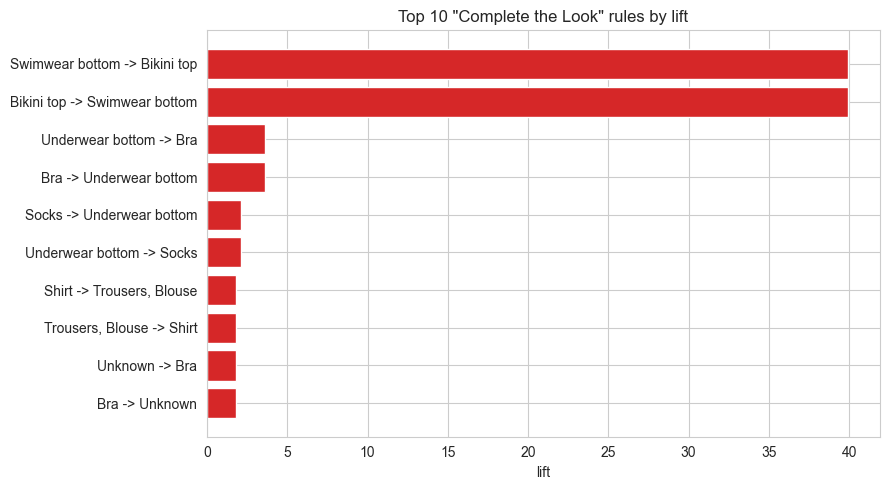

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
top_rules = rules.head(10).copy()
top_rules['pair'] = top_rules['antecedents'].apply(lambda x: ', '.join(x)) + ' -> ' + top_rules['consequents'].apply(lambda x: ', '.join(x))
ax.barh(top_rules['pair'][::-1], top_rules['lift'][::-1], color='#d62728')
ax.set_xlabel('lift')
ax.set_title('Top 10 "Complete the Look" rules by lift')
plt.tight_layout()
plt.show()


## 6. Wardrobe Fatigue (churn signal) — deferred

Skipping a real implementation here on purpose: detecting "stopped buying category X" needs enough calendar time to distinguish an actual lapse from someone who just hasn't re-ordered *yet* — not reliable over a 22-day window (nearly every customer would look "lapsed" in every category they didn't repurchase in three weeks).

Sketch for when a longer window (6–12 months) is available:

```
last_purchase_per_category = df.groupby(['customer_id', 'product_group_name'])['t_dat'].max()
days_since = snapshot_date - last_purchase_per_category
wardrobe_fatigued = days_since > category_specific_threshold   # e.g. 60-90 days, tune per category
```
Category-specific thresholds matter here — the natural repurchase gap for socks is very different from outerwear.


## 7. Export agent-ready feature tables

Two outputs a FastAPI backend would actually load: a per-customer feature table (RFM + CLTV) for the Retail Strategist / Economist agents, and the ARL rule table for "Complete the Look" recommendations.


In [14]:
customer_features = rfm.merge(
    cltv_c[['customer_id', 'cltv_score', 'cltv_segment']],
    on='customer_id', how='left'
)
customer_features.to_csv('customer_features.csv', index=False)

rules_export = rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].copy()
rules_export['antecedents'] = rules_export['antecedents'].apply(lambda x: ', '.join(x))
rules_export['consequents'] = rules_export['consequents'].apply(lambda x: ', '.join(x))
rules_export.to_csv('arl_rules.csv', index=False)

print("Saved customer_features.csv:", customer_features.shape)
print("Saved arl_rules.csv:", rules_export.shape)
customer_features.head()


Saved customer_features.csv: (189510, 11)
Saved arl_rules.csv: (240, 5)


,customer_id,Recency,Frequency,Monetary,R_score,F_score,M_score,RF_score,segment,cltv_score,cltv_segment
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,18,1,0.050831,2,1,2,21,hibernating,0.005263,C
1,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,8,1,0.061000,4,1,2,41,promising,0.007580,C
2,0000757967448a6cb83efb3ea7a3fb9d418ac7adf2379d...,9,1,0.076237,4,1,3,41,promising,0.011841,C
3,000172a9c322560c849754ffbdfdb2180d408aa7176b94...,19,1,0.101644,1,1,3,11,hibernating,0.021050,B
4,0001d44dbe7f6c4b35200abdb052c77a87596fe1bdcc37...,9,4,0.237966,4,5,5,45,loyal_customers,0.115387,A


## Next steps

- Pull a longer transaction window (6–12 months) to make Frequency/Churn/Wardrobe Fatigue meaningful, and revisit CLTV with BG/NBD + Gamma-Gamma once histories are long enough.
- `customer_features.csv` and `arl_rules.csv` are the two files to load into the FastAPI backend as the Retail Strategist / Economist agents' training ground, per the original plan.
- Mercari (filtered to apparel categories) is next for the resale-pricing regression model.
